# Part 2: Clinical-trial outcomes

Run from the project root or the Part 2 directory. The notebook reads the supplied outcome files and uses the Part 1 reason labels only for error analysis. It reproduces the submitted model and exports the validation tables used in the report.

## Loading the data and exploring it

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings("ignore")

PHASES = ["I", "II", "III"]
LABELS = ["Safety", "Funding", "Efficacy", "Recruitment", "Other"]

DATA = Path.cwd()
if not (DATA / "outcome_train.csv").is_file():
    DATA = DATA / "Part 2"

train = pd.read_csv(DATA / "outcome_train.csv")
val = pd.read_csv(DATA / "outcome_val.csv")
test = pd.read_csv(DATA / "outcome_test.csv")
print("shapes:", train.shape, val.shape, test.shape)

assert (len(train), len(val), len(test)) == (8037, 1013, 1500)
for frame in (train, val, test):
    assert frame["ID"].is_unique
    assert not frame.duplicated(["trial_id", "phase"]).any()
for first, second in ((train, val), (train, test), (val, test)):
    assert set(first["trial_id"]).isdisjoint(second["trial_id"])

shapes: (8037, 15) (1013, 15) (1500, 14)


In [2]:
# how many rows each phase has in every set
rows_per_phase = pd.DataFrame({
    "train": train["phase"].value_counts(),
    "val": val["phase"].value_counts(),
    "test": test["phase"].value_counts(),
}).reindex(PHASES)
print(rows_per_phase)

       train  val  test
phase                  
I       1012  149   500
II      3950  501   500
III     3075  363   500


In [3]:
# the mean of the 0/1 label is the share of successful trials
success_train = train.groupby("phase")["label"].mean()
success_val = val.groupby("phase")["label"].mean()

success = pd.DataFrame({"train": success_train, "val": success_val}).reindex(PHASES)
print(success.round(3))

       train    val
phase              
I      0.566  0.570
II     0.477  0.471
III    0.653  0.661


In [4]:
# train and val are from the same years and test is newer, like in Part 1
sets = {"train": train, "val": val, "test": test}

for name, df in sets.items():
    first_year = df["start_year"].min()
    last_year = df["start_year"].max()
    median_year = df["start_year"].median()
    n_missing = df["start_year"].isna().sum()
    print(f"{name:6s} years {first_year:.0f}–{last_year:.0f}, median {median_year:.0f}, missing {n_missing}")

train  years 1993–2013, median 2007, missing 21
val    years 1995–2013, median 2007, missing 6
test   years 2014–2021, median 2015, missing 0


In [5]:
# share of successful trials grouped by start year, train and val together
seen = pd.concat([train, val])
year_groups = pd.cut(seen["start_year"], bins=[1990, 2000, 2004, 2007, 2010, 2013],
                     labels=["up to 2000", "2001-04", "2005-07", "2008-10", "2011-13"])

success_by_year = seen.groupby(year_groups, observed=False)["label"].mean()
rows_by_year = year_groups.value_counts().sort_index()
print(pd.DataFrame({"success rate": success_by_year.round(3), "rows": rows_by_year}))

            success rate  rows
start_year                    
up to 2000         0.251   219
2001-04            0.423  1413
2005-07            0.561  3660
2008-10            0.586  2446
2011-13            0.678  1285


In [6]:
# the reasons from Part 1, real labels for the labeled trials and val, predictions for the rest
reason_labels = pd.read_csv(DATA.parent / "Part 1" / "reason_labels.csv")
assert reason_labels["ID"].is_unique
assert set(reason_labels["source"]) == {"true", "predicted"}
print("trials with reasons:", len(reason_labels))
print(reason_labels["source"].value_counts().to_dict())

# count failed validation rows that have a record in Part 1
failed_val = val[val["label"] == 0]
in_part1 = failed_val["trial_id"].isin(reason_labels["ID"])
print("failed val rows:", len(failed_val), "| with a Part 1 reason:", in_part1.sum())

trials with reasons: 1561
{'predicted': 1326, 'true': 235}
failed val rows: 452 | with a Part 1 reason: 198


## Preparing the text

In [7]:
# same text as the starter code, all four text columns joined together
text_columns = ["criteria", "diseases_cleaned", "drugs", "icdcodes"]

def trial_text(df):
    return df[text_columns].fillna("").agg(" ".join, axis=1)

In [8]:
from sklearn.metrics import f1_score, roc_auc_score, average_precision_score, log_loss

# scores of one phase, F1 needs 0/1 predictions so I cut the probability at 0.5
def evaluate(y_true, probs, name, phase):
    preds = (probs >= 0.5).astype(int)
    row = {
        "model": name,
        "phase": phase,
        "F1": f1_score(y_true, preds, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, probs),
        "PR-AUC": average_precision_score(y_true, probs),
        "log loss": log_loss(y_true, probs),
    }
    return row

In [9]:
# one row per phase for a model, probs has one value for every row of df
def evaluate_phases(df, probs, name):
    rows = []
    for phase in PHASES:
        in_phase = (df["phase"] == phase).values
        rows.append(evaluate(df["label"].values[in_phase], probs[in_phase], name, phase))
    return rows

# Kaggle scores the log loss averaged over the three phases, so I use that to compare models
def mean_scores(df, probs):
    rows = evaluate_phases(df, probs, "")
    mean_ll = np.mean([r["log loss"] for r in rows])
    mean_roc = np.mean([r["ROC-AUC"] for r in rows])
    return mean_ll, mean_roc

## Baseline from the starter code

In [10]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression

# the starter model, one bag of words logistic regression for every phase
val_probs_base = np.zeros(len(val))

for phase in PHASES:
    train_phase = train[train["phase"] == phase]
    in_phase = (val["phase"] == phase).values

    vectorizer = CountVectorizer(binary=True, min_df=3, max_features=20000)
    X_train_phase = vectorizer.fit_transform(trial_text(train_phase))
    X_val_phase = vectorizer.transform(trial_text(val[in_phase]))

    model = LogisticRegression(max_iter=500, solver="liblinear", random_state=42)
    model.fit(X_train_phase, train_phase["label"])
    val_probs_base[in_phase] = model.predict_proba(X_val_phase)[:, 1]

results = []
results.extend(evaluate_phases(val, val_probs_base, "starter BoW LR"))
pd.DataFrame(results).round(3)

Out[0]: 
            model phase     F1  ROC-AUC  PR-AUC  log loss
0  starter BoW LR     I  0.701    0.703   0.754     0.879
1  starter BoW LR    II  0.614    0.663   0.638     1.060
2  starter BoW LR   III  0.774    0.705   0.815     0.881


In [11]:
# for comparison, predicting the share of successful train trials of the phase for everyone
val_probs_rate = val["phase"].map(success_train).values

rate_ll, _ = mean_scores(val, val_probs_rate)
base_ll, base_roc = mean_scores(val, val_probs_base)
print(f"starter      mean log loss {base_ll:.3f} | mean ROC-AUC {base_roc:.3f}")
print(f"class rate   mean log loss {rate_ll:.3f}")

starter      mean log loss 0.940 | mean ROC-AUC 0.690
class rate   mean log loss 0.672


## Comparing text features and classifiers

In [12]:
# trains one model per phase with the vectorizer and the model I give it and returns the val probabilities
def fit_per_phase(make_vectorizer, make_model, fit_df=train, eval_df=val):
    probs = np.zeros(len(eval_df))

    for phase in PHASES:
        fit_phase = fit_df[fit_df["phase"] == phase]
        in_phase = (eval_df["phase"] == phase).values

        vectorizer = make_vectorizer()
        X_fit = vectorizer.fit_transform(trial_text(fit_phase))
        X_eval = vectorizer.transform(trial_text(eval_df[in_phase]))

        model = make_model()
        model.fit(X_fit, fit_phase["label"])
        probs[in_phase] = model.predict_proba(X_eval)[:, 1]

    return probs

In [13]:
# the starter model is very sure of itself, so first I try the same bag of words with smaller C
for C in [0.01, 0.03, 0.1, 0.3]:
    probs = fit_per_phase(lambda: CountVectorizer(binary=True, min_df=3, max_features=20000),
                          lambda: LogisticRegression(C=C, max_iter=2000))
    mean_ll, mean_roc = mean_scores(val, probs)
    print(f"BoW LR        C={C:<5} mean log loss {mean_ll:.3f} | mean ROC-AUC {mean_roc:.3f}")

BoW LR        C=0.01  mean log loss 0.592 | mean ROC-AUC 0.737
BoW LR        C=0.03  mean log loss 0.599 | mean ROC-AUC 0.730
BoW LR        C=0.1   mean log loss 0.647 | mean ROC-AUC 0.717
BoW LR        C=0.3   mean log loss 0.751 | mean ROC-AUC 0.703


In [14]:
from sklearn.feature_extraction.text import TfidfVectorizer

# TF-IDF gives less weight to words that are in every trial, I try single words and pairs of words
for ngrams in [(1, 1), (1, 2)]:
    for C in [0.3, 1, 3, 10]:
        probs = fit_per_phase(lambda: TfidfVectorizer(ngram_range=ngrams, min_df=3, max_features=50000, sublinear_tf=True),
                              lambda: LogisticRegression(C=C, max_iter=2000))
        mean_ll, mean_roc = mean_scores(val, probs)
        print(f"TF-IDF {str(ngrams):<7} C={C:<4} mean log loss {mean_ll:.3f} | mean ROC-AUC {mean_roc:.3f}")

TF-IDF (1, 1)  C=0.3  mean log loss 0.602 | mean ROC-AUC 0.745
TF-IDF (1, 1)  C=1    mean log loss 0.580 | mean ROC-AUC 0.752
TF-IDF (1, 1)  C=3    mean log loss 0.575 | mean ROC-AUC 0.749
TF-IDF (1, 1)  C=10   mean log loss 0.606 | mean ROC-AUC 0.736
TF-IDF (1, 2)  C=0.3  mean log loss 0.607 | mean ROC-AUC 0.752
TF-IDF (1, 2)  C=1    mean log loss 0.581 | mean ROC-AUC 0.760
TF-IDF (1, 2)  C=3    mean log loss 0.568 | mean ROC-AUC 0.760
TF-IDF (1, 2)  C=10   mean log loss 0.581 | mean ROC-AUC 0.754


In [15]:
from sklearn.naive_bayes import MultinomialNB

# Naive Bayes needs counts, not 0/1 or TF-IDF
for alpha in [0.1, 1, 10, 100]:
    probs = fit_per_phase(lambda: CountVectorizer(min_df=3, max_features=20000),
                          lambda: MultinomialNB(alpha=alpha))
    mean_ll, mean_roc = mean_scores(val, probs)
    print(f"Naive Bayes   alpha={alpha:<5} mean log loss {mean_ll:.3f} | mean ROC-AUC {mean_roc:.3f}")

Naive Bayes   alpha=0.1   mean log loss 6.993 | mean ROC-AUC 0.711
Naive Bayes   alpha=1     mean log loss 6.718 | mean ROC-AUC 0.714
Naive Bayes   alpha=10    mean log loss 6.157 | mean ROC-AUC 0.703
Naive Bayes   alpha=100   mean log loss 7.894 | mean ROC-AUC 0.622


In [16]:
from sklearn.neighbors import KNeighborsClassifier

# KNN looks at the most similar train trials, cosine works better than euclidean for text
for k in [10, 30, 60]:
    probs = fit_per_phase(lambda: TfidfVectorizer(min_df=3, max_features=20000, sublinear_tf=True),
                          lambda: KNeighborsClassifier(n_neighbors=k, metric="cosine", weights="distance"))
    mean_ll, mean_roc = mean_scores(val, probs)
    print(f"KNN cosine    k={k:<4} mean log loss {mean_ll:.3f} | mean ROC-AUC {mean_roc:.3f}")

KNN cosine    k=10   mean log loss 0.921 | mean ROC-AUC 0.731
KNN cosine    k=30   mean log loss 0.610 | mean ROC-AUC 0.745
KNN cosine    k=60   mean log loss 0.615 | mean ROC-AUC 0.739


In [17]:
# the best setting of each classifier goes in the results table
best_settings = {
    "BoW LR C=0.01": (lambda: CountVectorizer(binary=True, min_df=3, max_features=20000),
                      lambda: LogisticRegression(C=0.01, max_iter=2000)),
    "TF-IDF 1-2 grams LR C=3": (lambda: TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=50000, sublinear_tf=True),
                                lambda: LogisticRegression(C=3, max_iter=2000)),
    "Naive Bayes alpha=1": (lambda: CountVectorizer(min_df=3, max_features=20000),
                            lambda: MultinomialNB(alpha=1)),
    "KNN cosine k=30": (lambda: TfidfVectorizer(min_df=3, max_features=20000, sublinear_tf=True),
                        lambda: KNeighborsClassifier(n_neighbors=30, metric="cosine", weights="distance")),
}

val_probs_models = {}
for name, (make_vectorizer, make_model) in best_settings.items():
    val_probs_models[name] = fit_per_phase(make_vectorizer, make_model)
    results.extend(evaluate_phases(val, val_probs_models[name], name))

pd.DataFrame(results).round(3)

Out[0]: 
                      model phase     F1  ROC-AUC  PR-AUC  log loss
0            starter BoW LR     I  0.701    0.703   0.754     0.879
1            starter BoW LR    II  0.614    0.663   0.638     1.060
2            starter BoW LR   III  0.774    0.705   0.815     0.881
3             BoW LR C=0.01     I  0.781    0.757   0.790     0.597
4             BoW LR C=0.01    II  0.625    0.713   0.697     0.617
5             BoW LR C=0.01   III  0.799    0.743   0.851     0.562
6   TF-IDF 1-2 grams LR C=3     I  0.763    0.780   0.824     0.569
7   TF-IDF 1-2 grams LR C=3    II  0.614    0.724   0.714     0.606
8   TF-IDF 1-2 grams LR C=3   III  0.812    0.775   0.872     0.529
9       Naive Bayes alpha=1     I  0.684    0.717   0.749     5.834
10      Naive Bayes alpha=1    II  0.636    0.694   0.633     8.125
11      Naive Bayes alpha=1   III  0.784    0.732   0.828     6.197
12          KNN cosine k=30     I  0.737    0.752   0.822     0.591
13          KNN cosine k=30    II  0.61

In [18]:
# TF-IDF with pairs of words has the lowest log loss so it is my original model
val_probs_orig = val_probs_models["TF-IDF 1-2 grams LR C=3"]

orig_ll, orig_roc = mean_scores(val, val_probs_orig)
print(f"original model   mean log loss {orig_ll:.3f} | mean ROC-AUC {orig_roc:.3f}")

original model   mean log loss 0.568 | mean ROC-AUC 0.760


## Error analysis by stopping reason

In [19]:
# every failed val row with the probability of success from the original model
failed = val[val["label"] == 0][["ID", "trial_id", "phase"]].copy()
failed["prob_orig"] = val_probs_orig[(val["label"] == 0).values]

# each trial is in a phase only once, so nobody is counted twice inside a phase
print("same trial twice in a phase:", failed.duplicated(["trial_id", "phase"]).any())

same trial twice in a phase: False


In [20]:
# join the Part 1 reasons; an unmatched row has no recorded reason
reasons = reason_labels[["ID", "source"] + LABELS].rename(columns={"ID": "trial_id"})
failed = failed.merge(reasons, on="trial_id", how="left", validate="many_to_one", sort=False)
failed["no reason"] = failed["source"].isna().astype(int)
failed[LABELS] = failed[LABELS].fillna(0).astype(int)

print("failed rows:", len(failed))
print("reason from a real label:", (failed["source"] == "true").sum())
print("reason from a Part 1 prediction:", (failed["source"] == "predicted").sum())
print("no recorded stopping reason:", failed["no reason"].sum())

failed rows: 452
reason from a real label: 27
reason from a Part 1 prediction: 171
no recorded stopping reason: 254


In [21]:
# for each phase and reason, the number of failed trials and the share the model called successful
GROUPS = LABELS + ["no reason"]

def error_table(failed_df, prob_col):
    rows = []
    for group in GROUPS + ["all failed"]:
        row = {"reason": group}
        for phase in PHASES:
            in_group = failed_df["phase"] == phase
            if group != "all failed":
                in_group = in_group & (failed_df[group] == 1)
            n = in_group.sum()
            wrong = (failed_df.loc[in_group, prob_col] >= 0.5).mean() if n > 0 else np.nan
            row[f"{phase} n"] = n
            row[f"{phase} wrong"] = wrong
        rows.append(row)
    return pd.DataFrame(rows).set_index("reason")

errors_orig = error_table(failed, "prob_orig")
errors_orig.round(3)

Out[0]: 
             I n  I wrong  II n  II wrong  III n  III wrong
reason                                                     
Safety         8    0.375    13     0.462      8      0.500
Funding        4    0.500     4     0.250      0        NaN
Efficacy       2    1.000    10     0.300      8      0.875
Recruitment   23    0.391    89     0.225     22      0.636
Other          4    0.500    21     0.381     11      0.727
no reason     28    0.536   144     0.347     82      0.573
all failed    64    0.469   265     0.309    123      0.593


In [22]:
# same table only with the reasons that come from real labels, to see if the predicted ones change the picture
errors_true_only = error_table(failed[failed["source"] == "true"], "prob_orig")
errors_true_only.round(3)

Out[0]: 
             I n  I wrong  II n  II wrong  III n  III wrong
reason                                                     
Safety         1     0.00     1     0.000      1      0.000
Funding        1     0.00     1     0.000      0        NaN
Efficacy       0      NaN     0       NaN      0        NaN
Recruitment    2     0.50    12     0.250      5      0.400
Other          0      NaN     3     1.000      2      1.000
no reason      0      NaN     0       NaN      0        NaN
all failed     4     0.25    16     0.312      7      0.429


In [23]:
# the share of failed trials called successful next to the share of trials that really succeed
for phase in PHASES:
    wrong = errors_orig.loc["all failed", f"{phase} wrong"]
    print(f"phase {phase:<4} failed trials called successful {wrong:.3f} | success rate in train {success_train[phase]:.3f}")

phase I    failed trials called successful 0.469 | success rate in train 0.566
phase II   failed trials called successful 0.309 | success rate in train 0.477
phase III  failed trials called successful 0.593 | success rate in train 0.653


The share of failed trials that the model calls successful follows the phase more than the reason: 0.593 in Phase III, 0.469 in Phase I and 0.309 in Phase II, in the same order as the success rates of the phases (0.653, 0.566 and 0.477). The ordering is consistent with the different success rates across phases.

Most failed trials (254 of 452) have no Part 1 record. In Phase III, the model calls 57% of those unmatched trials successful. Among the reasons, Recruitment in Phase II has the lowest rate (0.225 of 89 trials), maybe because trials that struggle to enroll have strict criteria that show up in the text. Efficacy in Phase III is the worst, with 7 of 8 trials called successful. Eligibility text may have little signal about whether a treatment works.

Most groups are very small, for example Funding has 4 trials in Phase I and II and none in Phase III, so one trial moves the rate by 0.125 or more and I would not read much into them. Also 171 of the 198 reasons are Part 1 predictions, and in Part 1 Other (F1 0.545) and Funding (F1 0.667) were the hardest reasons, so these groups are the least reliable. With only the 27 real labels each group has 0 to 12 trials, which is too few to compare.

Since the errors follow the phase, I try four changes: one model for all phases so Phase I, which has only 1012 train rows, can borrow from the others, information about the drug, the start year since success goes up over time, and averaging in KNN so trials on the same disease and drug count more.

## Improving the classifier

In [24]:
# like in Part 1 I also train on older trials and score on newer ones, because test is from 2014 on
# trials up to 2010 are the older ones, the train and val trials from 2011 to 2013 are the newer ones
older = train[train["start_year"] <= 2010]
newer = pd.concat([train[train["start_year"] > 2010], val[val["start_year"] > 2010]], ignore_index=True)

print("older rows:", len(older), "| newer rows:", len(newer))
print("success rate older:", round(older["label"].mean(), 3), "| newer:", round(newer["label"].mean(), 3))

older rows: 6885 | newer rows: 1285
success rate older: 0.536 | newer: 0.678


In [25]:
# fit_fn trains on the first set and returns probabilities for the second one
# I run it on train -> val and on older -> newer and print both mean log losses
def check_both(fit_fn, name):
    probs_val = fit_fn(train, val)
    probs_newer = fit_fn(older, newer)

    val_ll, val_roc = mean_scores(val, probs_val)
    newer_ll, newer_roc = mean_scores(newer, probs_newer)
    print(f"{name:<34} val log loss {val_ll:.3f} ROC-AUC {val_roc:.3f} | newer log loss {newer_ll:.3f} ROC-AUC {newer_roc:.3f}")
    return probs_val, probs_newer

In [26]:
# the original model in the same format so I can compare with it
tfidf = lambda: TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=50000, sublinear_tf=True)

def fit_original(fit_df, eval_df):
    return fit_per_phase(tfidf, lambda: LogisticRegression(C=3, max_iter=2000), fit_df, eval_df)

orig_val, orig_newer = check_both(fit_original, "original (TF-IDF LR per phase)")

original (TF-IDF LR per phase)     val log loss 0.568 ROC-AUC 0.760 | newer log loss 0.554 ROC-AUC 0.684


In [27]:
import scipy.sparse as sp

# extra columns next to the text: the start year scaled like in Part 1 and a flag for a matched drug
def extra_columns(df, use_year, use_drug, year_reference=None):
    cols = []
    if use_year:
        years_seen = year_reference["start_year"]
        year = df["start_year"].fillna(years_seen.median())
        cols.append(((year - years_seen.mean()) / years_seen.std()).values.reshape(-1, 1))
    if use_drug:
        has_drug = df["drug_smiles"].notna().astype(float)
        cols.append(has_drug.values.reshape(-1, 1))
    return sp.csr_matrix(np.hstack(cols))

In [28]:
# same as fit_per_phase with TF-IDF but with the extra columns added
def fit_per_phase_extra(fit_df, eval_df, use_year, use_drug, C=3):
    probs = np.zeros(len(eval_df))

    for phase in PHASES:
        fit_phase = fit_df[fit_df["phase"] == phase]
        in_phase = (eval_df["phase"] == phase).values
        eval_phase = eval_df[in_phase]

        vectorizer = tfidf()
        X_fit = sp.hstack([vectorizer.fit_transform(trial_text(fit_phase)), extra_columns(fit_phase, use_year, use_drug, year_reference=fit_df)]).tocsr()
        X_eval = sp.hstack([vectorizer.transform(trial_text(eval_phase)), extra_columns(eval_phase, use_year, use_drug, year_reference=fit_df)]).tocsr()

        model = LogisticRegression(C=C, max_iter=3000)
        model.fit(X_fit, fit_phase["label"])
        probs[in_phase] = model.predict_proba(X_eval)[:, 1]

    return probs

In [29]:
_ = check_both(lambda a, b: fit_per_phase_extra(a, b, use_year=True, use_drug=False), "per phase + start year")
_ = check_both(lambda a, b: fit_per_phase_extra(a, b, use_year=False, use_drug=True), "per phase + drug flag")

per phase + start year             val log loss 0.570 ROC-AUC 0.756 | newer log loss 0.553 ROC-AUC 0.686
per phase + drug flag              val log loss 0.566 ROC-AUC 0.762 | newer log loss 0.552 ROC-AUC 0.688


In [30]:
# Phase I has only 1012 train rows, so I try one model for all phases with a column for each phase
# the words are shared and the phase columns let each phase have its own base rate
def phase_columns(df):
    dummies = pd.get_dummies(df["phase"]).reindex(columns=PHASES, fill_value=0)
    return sp.csr_matrix(dummies.values.astype(float))

def fit_pooled(fit_df, eval_df, C=3, use_year=False, use_drug=False):
    vectorizer = tfidf()
    X_fit = [vectorizer.fit_transform(trial_text(fit_df)), phase_columns(fit_df)]
    X_eval = [vectorizer.transform(trial_text(eval_df)), phase_columns(eval_df)]
    if use_year or use_drug:
        X_fit.append(extra_columns(fit_df, use_year, use_drug, year_reference=fit_df))
        X_eval.append(extra_columns(eval_df, use_year, use_drug, year_reference=fit_df))

    model = LogisticRegression(C=C, max_iter=3000)
    model.fit(sp.hstack(X_fit).tocsr(), fit_df["label"])
    return model.predict_proba(sp.hstack(X_eval).tocsr())[:, 1]

In [31]:
for C in [1, 2, 3, 5]:
    _ = check_both(lambda a, b: fit_pooled(a, b, C=C), f"pooled C={C}")

pooled C=1                         val log loss 0.565 ROC-AUC 0.767 | newer log loss 0.541 ROC-AUC 0.726
pooled C=2                         val log loss 0.558 ROC-AUC 0.769 | newer log loss 0.539 ROC-AUC 0.720
pooled C=3                         val log loss 0.558 ROC-AUC 0.770 | newer log loss 0.542 ROC-AUC 0.714
pooled C=5                         val log loss 0.562 ROC-AUC 0.768 | newer log loss 0.548 ROC-AUC 0.710


In [32]:
# C=2 and C=3 are the same on val and C=2 is a bit better on the newer trials
# I keep C=2 for now and check it again at the end
POOLED_C = 2

In [33]:
_ = check_both(lambda a, b: fit_pooled(a, b, C=POOLED_C, use_year=True), "pooled + start year")
pooled_val, pooled_newer = check_both(lambda a, b: fit_pooled(a, b, C=POOLED_C, use_drug=True), "pooled + drug flag")

pooled + start year                val log loss 0.559 ROC-AUC 0.768 | newer log loss 0.541 ROC-AUC 0.721
pooled + drug flag                 val log loss 0.557 ROC-AUC 0.772 | newer log loss 0.538 ROC-AUC 0.720


In [34]:
from rdkit import Chem, RDLogger
from rdkit.Chem import rdFingerprintGenerator
RDLogger.DisableLog("rdApp.*")

# Morgan fingerprints of the drugs, same function as in Part 1
gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=1024)

def trial_fingerprint(smiles_field):
    if pd.isna(smiles_field):
        return np.zeros(1024)

    fps = []
    for s in smiles_field.split(";"):
        mol = Chem.MolFromSmiles(s)
        if mol is not None:
            fps.append(gen.GetFingerprintAsNumPy(mol))

    if len(fps) == 0:
        return np.zeros(1024)
    return np.max(fps, axis=0)

In [35]:
# I compute the fingerprint of every different SMILES string once since many trials share drugs
all_smiles = pd.concat([train["drug_smiles"], val["drug_smiles"], test["drug_smiles"]]).dropna().unique()
fingerprint_of = {s: trial_fingerprint(s) for s in all_smiles}

def fingerprints(df):
    rows = [fingerprint_of[s] if isinstance(s, str) else np.zeros(1024) for s in df["drug_smiles"]]
    return sp.csr_matrix(np.vstack(rows))

print("different drug combinations:", len(fingerprint_of))

different drug combinations: 1576


In [36]:
# pooled model with the drug flag and the fingerprints
# the 1024 bits would take over the TF-IDF columns so I scale them down
def fit_pooled_fp(fit_df, eval_df, fp_weight, C=POOLED_C):
    vectorizer = tfidf()
    X_fit = sp.hstack([vectorizer.fit_transform(trial_text(fit_df)), phase_columns(fit_df),
                       extra_columns(fit_df, False, True), fingerprints(fit_df) * fp_weight]).tocsr()
    X_eval = sp.hstack([vectorizer.transform(trial_text(eval_df)), phase_columns(eval_df),
                        extra_columns(eval_df, False, True), fingerprints(eval_df) * fp_weight]).tocsr()

    model = LogisticRegression(C=C, max_iter=3000)
    model.fit(X_fit, fit_df["label"])
    return model.predict_proba(X_eval)[:, 1]

for w in [0.05, 0.1, 0.2]:
    _ = check_both(lambda a, b: fit_pooled_fp(a, b, w), f"pooled + drug flag + fingerprints {w}")

pooled + drug flag + fingerprints 0.05 val log loss 0.556 ROC-AUC 0.770 | newer log loss 0.539 ROC-AUC 0.721
pooled + drug flag + fingerprints 0.1 val log loss 0.556 ROC-AUC 0.770 | newer log loss 0.541 ROC-AUC 0.719
pooled + drug flag + fingerprints 0.2 val log loss 0.555 ROC-AUC 0.770 | newer log loss 0.545 ROC-AUC 0.717


In [37]:
# KNN per phase like before, it finds trials on the same disease and drug
def fit_knn(fit_df, eval_df, k=30):
    return fit_per_phase(lambda: TfidfVectorizer(min_df=3, max_features=20000, sublinear_tf=True),
                         lambda: KNeighborsClassifier(n_neighbors=k, metric="cosine", weights="distance"),
                         fit_df, eval_df)

knn_runs = {}
for k in [20, 30, 50]:
    knn_runs[k] = check_both(lambda a, b: fit_knn(a, b, k), f"KNN k={k}")

KNN k=20                           val log loss 0.670 ROC-AUC 0.743 | newer log loss 0.650 ROC-AUC 0.686
KNN k=30                           val log loss 0.610 ROC-AUC 0.745 | newer log loss 0.571 ROC-AUC 0.703
KNN k=50                           val log loss 0.612 ROC-AUC 0.744 | newer log loss 0.551 ROC-AUC 0.701


In [38]:
# KNN alone is worse but it makes different mistakes, so I average it with the pooled model
# the weight is how much the KNN counts in the average
for k, (knn_val, knn_newer) in knn_runs.items():
    for w in [0.3, 0.5]:
        val_ll, val_roc = mean_scores(val, (1 - w) * pooled_val + w * knn_val)
        newer_ll, newer_roc = mean_scores(newer, (1 - w) * pooled_newer + w * knn_newer)
        print(f"pooled + KNN k={k:<3} weight {w:<4} val log loss {val_ll:.3f} ROC-AUC {val_roc:.3f} | newer log loss {newer_ll:.3f} ROC-AUC {newer_roc:.3f}")

pooled + KNN k=20  weight 0.3  val log loss 0.553 ROC-AUC 0.775 | newer log loss 0.534 ROC-AUC 0.724
pooled + KNN k=20  weight 0.5  val log loss 0.555 ROC-AUC 0.772 | newer log loss 0.535 ROC-AUC 0.720
pooled + KNN k=30  weight 0.3  val log loss 0.554 ROC-AUC 0.776 | newer log loss 0.532 ROC-AUC 0.728
pooled + KNN k=30  weight 0.5  val log loss 0.557 ROC-AUC 0.774 | newer log loss 0.533 ROC-AUC 0.727
pooled + KNN k=50  weight 0.3  val log loss 0.556 ROC-AUC 0.776 | newer log loss 0.534 ROC-AUC 0.725
pooled + KNN k=50  weight 0.5  val log loss 0.559 ROC-AUC 0.774 | newer log loss 0.535 ROC-AUC 0.726


In [39]:
# k=20 and k=30 with weight 0.3 are almost the same on val and k=30 is better on the newer trials, so I keep k=30 with weight 0.3
# the fingerprints changed val by 0.001 or less and made the newer trials worse, and adding the start year did not improve official validation, so I leave both features out
KNN_K = 30
KNN_WEIGHT = 0.3

def fit_improved(fit_df, eval_df, C):
    probs_pooled = fit_pooled(fit_df, eval_df, C=C, use_drug=True)
    probs_knn = fit_knn(fit_df, eval_df, KNN_K)
    return (1 - KNN_WEIGHT) * probs_pooled + KNN_WEIGHT * probs_knn

In [40]:
# now that the KNN is in the average I check the C of the pooled model again
for C in [2, 3]:
    _ = check_both(lambda a, b: fit_improved(a, b, C), f"pooled C={C} + drug flag + KNN")

pooled C=2 + drug flag + KNN       val log loss 0.554 ROC-AUC 0.776 | newer log loss 0.532 ROC-AUC 0.728
pooled C=3 + drug flag + KNN       val log loss 0.551 ROC-AUC 0.777 | newer log loss 0.532 ROC-AUC 0.724


In [41]:
# C=3 is better on val and the same on the newer trials, so the final model uses C=3
POOLED_C = 3
val_probs_impr, newer_probs_impr = check_both(lambda a, b: fit_improved(a, b, POOLED_C), "improved (pooled + drug flag + KNN)")

improved (pooled + drug flag + KNN) val log loss 0.551 ROC-AUC 0.777 | newer log loss 0.532 ROC-AUC 0.724


## Comparing the original and the improved model

In [42]:
# all the scores of the two models for each phase
compare = pd.DataFrame(evaluate_phases(val, val_probs_orig, "original") + evaluate_phases(val, val_probs_impr, "improved"))
compare.pivot(index="phase", columns="model", values=["F1", "ROC-AUC", "PR-AUC", "log loss"]).round(3)

Out[0]: 
            F1           ROC-AUC            PR-AUC          log loss         
model improved original improved original improved original improved original
phase                                                                        
I        0.753    0.763    0.790    0.780    0.840    0.824    0.556    0.569
II       0.655    0.614    0.744    0.724    0.725    0.714    0.592    0.606
III      0.835    0.812    0.798    0.775    0.881    0.872    0.506    0.529


In [43]:
# the error rates by reason for both models next to each other
failed["prob_impr"] = val_probs_impr[(val["label"] == 0).values]
errors_impr = error_table(failed, "prob_impr")

side_by_side = pd.DataFrame(index=errors_orig.index)
for phase in PHASES:
    side_by_side[f"{phase} n"] = errors_orig[f"{phase} n"]
    side_by_side[f"{phase} original"] = errors_orig[f"{phase} wrong"]
    side_by_side[f"{phase} improved"] = errors_impr[f"{phase} wrong"]
side_by_side.round(3)

Out[0]: 
             I n  I original  I improved  ...  III n  III original  III improved
reason                                    ...                                   
Safety         8       0.375       0.500  ...      8         0.500         0.500
Funding        4       0.500       0.500  ...      0           NaN           NaN
Efficacy       2       1.000       0.500  ...      8         0.875         0.750
Recruitment   23       0.391       0.304  ...     22         0.636         0.636
Other          4       0.500       0.500  ...     11         0.727         0.636
no reason     28       0.536       0.464  ...     82         0.573         0.561
all failed    64       0.469       0.406  ...    123         0.593         0.577

[7 rows x 9 columns]


In [44]:
# recall on the successful trials, since calling more trials successful also catches more of the real ones
for phase in PHASES:
    is_success = ((val["phase"] == phase) & (val["label"] == 1)).values
    recall_orig = (val_probs_orig[is_success] >= 0.5).mean()
    recall_impr = (val_probs_impr[is_success] >= 0.5).mean()
    print(f"phase {phase:<4} recall original {recall_orig:.3f} | improved {recall_impr:.3f}")

phase I    recall original 0.835 | improved 0.788
phase II   recall original 0.597 | improved 0.644
phase III  recall original 0.892 | improved 0.929


In [45]:
# the scores on the newer trials for each phase, the closest thing to test I have
newer_compare = pd.DataFrame(evaluate_phases(newer, orig_newer, "original") + evaluate_phases(newer, newer_probs_impr, "improved"))
newer_compare.pivot(index="phase", columns="model", values=["ROC-AUC", "log loss"]).round(3)

Out[0]: 
       ROC-AUC          log loss         
model improved original improved original
phase                                    
I        0.672    0.626    0.602    0.625
II       0.766    0.742    0.573    0.591
III      0.734    0.685    0.420    0.447


The improved model has a lower log loss in every phase (0.569 to 0.556 in Phase I, 0.606 to 0.592 in Phase II and 0.529 to 0.506 in Phase III) and a higher ROC-AUC and PR-AUC everywhere. F1 goes up in Phase II and III but down in Phase I (0.763 to 0.753), because the improved model calls fewer Phase I trials successful and recall drops from 0.835 to 0.788. That is the trade-off of the change.

The share of failed trials called successful goes down in every phase (0.469 to 0.406, 0.309 to 0.287 and 0.593 to 0.577). Inside each reason the changes are only one or two trials, for example Recruitment in Phase I goes from 0.391 to 0.304 (2 of 23 trials) and Safety in Phase II from 0.462 to 0.308 (2 of 13), while Safety in Phase I goes up from 0.375 to 0.500 (1 of 8). The error rates still follow the phase, so the main problem from the error analysis is smaller but not gone.

The start year did not improve official validation even though the success rate goes from 0.251 before 2000 to 0.678 in 2011-13. My guess is that the text already shows when a trial was run, so the year adds little.

On the newer trials the ROC-AUC of the improved model drops from 0.777 on val to 0.724, so the model ranks newer trials worse. Its log loss there is lower (0.532), probably because newer trials succeed more often (0.678 against 0.536 for the older ones) and the model leans toward success. The improved model is better than the original in every phase on the newer trials too, so the gain is not only luck on val. Test starts in 2014, even later than these trials, so I expect the test log loss to be worse than on val.

## Writing the test predictions

In [46]:
# reproduce the submitted model: refit the selected settings on train and val
train_val = pd.concat([train, val], ignore_index=True)

test_probs = fit_improved(train_val, test, POOLED_C)
# log loss gets huge for a confident mistake, so I keep the probabilities away from 0 and 1
test_probs = np.clip(test_probs, 0.001, 0.999)

print("trained on", len(train_val), "rows")
print("test probabilities from", round(test_probs.min(), 3), "to", round(test_probs.max(), 3))

trained on 9050 rows
test probabilities from 0.105 to 0.976


In [47]:
# average predicted success per phase compared with the real success rate in train and val
test_mean = pd.Series(test_probs, index=test.index).groupby(test["phase"]).mean()
seen_rate = train_val.groupby("phase")["label"].mean()
print(pd.DataFrame({"train + val success rate": seen_rate, "mean test prediction": test_mean}).reindex(PHASES).round(3))

       train + val success rate  mean test prediction
phase                                                
I                         0.567                 0.588
II                        0.476                 0.549
III                       0.654                 0.719


In [48]:
# format of the Kaggle submission
sample_sub = pd.read_csv(DATA / "part2_sample_submission.csv")
print(sample_sub.head())

            ID  label
0  TR11252_III    0.5
1   TR08672_II    0.5
2    TR07815_I    0.5
3    TR08013_I    0.5
4   TR05100_II    0.5


In [49]:
# one row per test row with the ID and the probability of success, in the same order as the sample
submission = pd.DataFrame({"ID": test["ID"].values, "label": test_probs})
submission = submission.set_index("ID").loc[sample_sub["ID"]].reset_index()
assert list(sample_sub.columns) == ["ID", "label"]
assert len(submission) == 1500 and submission["ID"].is_unique
assert submission["ID"].equals(sample_sub["ID"])
assert np.isfinite(submission["label"]).all()
assert submission["label"].between(0, 1, inclusive="neither").all()
submission.to_csv(DATA / "part2_submission.csv", index=False)

print(submission.head())
print("rows:", len(submission))
print("same IDs in the same order as the sample submission:", (submission["ID"].values == sample_sub["ID"].values).all())
print("all probabilities between 0 and 1:", submission["label"].between(0, 1, inclusive="neither").all())

            ID     label
0  TR11252_III  0.620956
1   TR08672_II  0.636457
2    TR07815_I  0.586886
3    TR08013_I  0.603205
4   TR05100_II  0.471602
rows: 1500
same IDs in the same order as the sample submission: True
all probabilities between 0 and 1: True


## Report tables

We compare the original phase-specific model with the improved ensemble using the same validation rows and a threshold of 0.5. The pooled row shows F1, ROC-AUC and average precision across all validation rows. Its log loss uses equal phase weights, matching the competition test set. The stopping-reason table counts a failed trial in each of its reasons within a phase. We retain the source of each reason and use an empty rate for a group with no rows.

In [50]:
report_metrics = compare.copy()
for name, probabilities in (("original", val_probs_orig), ("improved", val_probs_impr)):
    pooled = evaluate(val["label"].to_numpy(), probabilities, name, "all")
    pooled["log loss"] = mean_scores(val, probabilities)[0]
    report_metrics.loc[len(report_metrics)] = pooled
report_metrics.to_csv(DATA / "part2_validation_metrics.csv", index=False)
display(report_metrics.round(4))

reason_rows = []
for phase in PHASES:
    phase_rows = failed.loc[failed["phase"].eq(phase)]
    for group in GROUPS + ["all failed"]:
        rows = phase_rows if group == "all failed" else phase_rows.loc[phase_rows[group].eq(1)]
        reason_rows.append({
            "phase": phase, "reason": group, "n": len(rows),
            "n_true": rows["source"].eq("true").sum(),
            "n_predicted": rows["source"].eq("predicted").sum(),
            "n_unrecorded": rows["source"].isna().sum(),
            "original_fp": rows["prob_orig"].ge(0.5).sum(),
            "improved_fp": rows["prob_impr"].ge(0.5).sum(),
        })

report_reasons = pd.DataFrame(reason_rows)
assert report_reasons[["n_true", "n_predicted", "n_unrecorded"]].sum(axis=1).eq(report_reasons["n"]).all()
for model in ("original", "improved"):
    report_reasons[f"{model}_fpr"] = report_reasons[f"{model}_fp"] / report_reasons["n"].replace(0, np.nan)
report_reasons.to_csv(DATA / "part2_stopping_reason_errors.csv", index=False)
display(report_reasons.round(4))

,model,phase,F1,ROC-AUC,PR-AUC,log loss
0,original,I,0.7634,0.7798,0.8242,0.5688
1,original,II,0.6144,0.7241,0.7139,0.6062
2,original,III,0.8121,0.7748,0.8717,0.5293
3,improved,I,0.7528,0.7897,0.8403,0.5555
4,improved,II,0.6552,0.7444,0.7249,0.5923
5,improved,III,0.8352,0.7978,0.8812,0.5056
6,original,all,0.7270,0.7649,0.8062,0.5681
7,improved,all,0.7517,0.7843,0.8199,0.5511


,phase,reason,n,n_true,n_predicted,n_unrecorded,original_fp,improved_fp,original_fpr,improved_fpr
0,I,Safety,8,1,7,0,3,4,0.3750,0.5000
1,I,Funding,4,1,3,0,2,2,0.5000,0.5000
2,I,Efficacy,2,0,2,0,2,1,1.0000,0.5000
3,I,Recruitment,23,2,21,0,9,7,0.3913,0.3043
4,I,Other,4,0,4,0,2,2,0.5000,0.5000
5,I,no reason,28,0,0,28,15,13,0.5357,0.4643
6,I,all failed,64,4,32,28,30,26,0.4688,0.4062
7,II,Safety,13,1,12,0,6,4,0.4615,0.3077
8,II,Funding,4,1,3,0,1,0,0.2500,0.0000
9,II,Efficacy,10,0,10,0,3,3,0.3000,0.3000


## Probability calibration

Log loss depends on probability quality. We compare the submitted ensemble's raw probabilities with sigmoid and isotonic calibration. For each training cohort, three grouped folds give predictions for trials held out of model fitting. We keep both rows of a combined-phase trial in one fold. Then we fit a separate calibration map for each phase using only those held-out predictions and their training labels. For the calendar check, the maps use only the earlier training cohort.

In [51]:
from sklearn.calibration import calibration_curve
from sklearn.isotonic import IsotonicRegression
from sklearn.model_selection import StratifiedGroupKFold
import matplotlib.pyplot as plt

def held_out_blend(fit_df):
    folds = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=5785)
    phase_and_label = fit_df["phase"] + "_" + fit_df["label"].astype(str)
    probabilities = np.full(len(fit_df), np.nan)
    for fit_idx, held_idx in folds.split(fit_df, phase_and_label, groups=fit_df["trial_id"]):
        fit_fold = fit_df.iloc[fit_idx]
        held_fold = fit_df.iloc[held_idx]
        assert set(fit_fold["trial_id"]).isdisjoint(held_fold["trial_id"])
        probabilities[held_idx] = fit_improved(fit_fold, held_fold, POOLED_C)
    assert np.isfinite(probabilities).all()
    return probabilities

def log_odds_column(probabilities):
    clipped = np.clip(probabilities, 1e-6, 1 - 1e-6)
    return np.log(clipped / (1 - clipped)).reshape(-1, 1)

def check_calibration(fit_df, eval_df, raw):
    held_out = held_out_blend(fit_df)
    sigmoid = np.empty(len(eval_df))
    isotonic = np.empty(len(eval_df))
    for phase in PHASES:
        fit_mask = fit_df["phase"].eq(phase).to_numpy()
        eval_mask = eval_df["phase"].eq(phase).to_numpy()
        labels = fit_df.loc[fit_mask, "label"]
        model = LogisticRegression(C=1000, max_iter=1000)
        model.fit(log_odds_column(held_out[fit_mask]), labels)
        sigmoid[eval_mask] = model.predict_proba(log_odds_column(raw[eval_mask]))[:, 1]
        monotone = IsotonicRegression(out_of_bounds="clip")
        monotone.fit(held_out[fit_mask], labels)
        isotonic[eval_mask] = monotone.predict(raw[eval_mask])
    return {"Raw": raw, "Sigmoid": sigmoid, "Isotonic": np.clip(isotonic, 0.001, 0.999)}

calibration_runs = {
    "Official validation": check_calibration(train, val, val_probs_impr),
    "2011--2013": check_calibration(older, newer, newer_probs_impr),
}
calibration_rows = []
for split, rows in (("Official validation", val), ("2011--2013", newer)):
    for method, probabilities in calibration_runs[split].items():
        loss, roc_auc = mean_scores(rows, probabilities)
        calibration_rows.append({"split": split, "method": method, "log loss": loss, "ROC-AUC": roc_auc})
calibration_table = pd.DataFrame(calibration_rows)
calibration_table.to_csv(DATA / "part2_calibration_metrics.csv", index=False)
display(calibration_table.round(4))

,split,method,log loss,ROC-AUC
0,Official validation,Raw,0.5511,0.7773
1,Official validation,Sigmoid,0.5506,0.7773
2,Official validation,Isotonic,0.5491,0.7785
3,2011--2013,Raw,0.5317,0.7243
4,2011--2013,Sigmoid,0.5321,0.7243
5,2011--2013,Isotonic,0.5419,0.7190


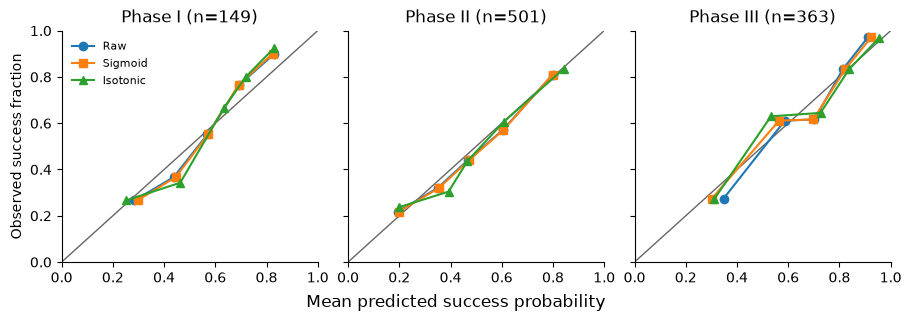

In [52]:
fig, axes = plt.subplots(1, 3, figsize=(9.0, 3.1), sharex=True, sharey=True, layout="constrained")
for phase, ax in zip(PHASES, axes):
    mask = val["phase"].eq(phase).to_numpy()
    ax.plot([0, 1], [0, 1], color="#666666", linewidth=1)
    for (method, probabilities), marker in zip(calibration_runs["Official validation"].items(), "os^"):
        fraction, average = calibration_curve(
            val.loc[mask, "label"], probabilities[mask], n_bins=5, strategy="quantile"
        )
        ax.plot(average, fraction, marker=marker, label=method)
    ax.set(title=f"Phase {phase} (n={mask.sum()})", xlim=(0, 1), ylim=(0, 1))
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Observed success fraction")
axes[0].legend(frameon=False, fontsize=8)
fig.supxlabel("Mean predicted success probability")
plt.show()